# 03 — Implicit ALS Matrix Factorization (MF): Kapsamlı Validation Analizi, Karşılaştırma ve Örnek Öneriler

Bu notebook, **Amazon Reviews 2023 (Video Games)** İşbirlikçi Filtreleme (CF) katmanında geliştirilen ve validation seti (`N = 75.799` kullanıcı) üzerinde hiperparametreleri dondurulmuş olan **Implicit ALS Matrix Factorization (`ALSModel`)** modelini tüm boyutlarıyla inceler ve mevcut referans modellerle (**Popularity**, **Item-kNN `pw=0.0`**, **Item-kNN `pw=0.01`**) karşılaştırır.

> **Kurallar ve Metodolojik Çerçeve:**
> - **Yalnızca Validation:** Bu notebook'ta `test.csv` ve `test_candidates` verilerine **hiçbir şekilde dokunulmamıştır**. Tüm metrikler, kırılımlar ve örnekler `val.csv` (`N = 75.799` kullanıcı) ve `train.csv` (`94.745 × 25.610`, `504.975` pozitif etkileşim) üzerinde üretilmiştir.
> - **Dondurulmuş ALS Konfigürasyonu (`saved_models/mf/`):** `factors=32`, `regularization=0.01`, `alpha=150.0`, `iterations=50`, `random_state=42`, `num_threads=1`, `fold_in_method='ridge'`.
> - **Ortak Değerlendirme Sözleşmesi:** Tüm modeller `ContractAdapter` (`src/contract.py`) ve `evaluate()` (`src/evaluation.py`, `TIE_BREAK_SEED = 42`) üzerinden birebir aynı kurallarla değerlendirilmiştir.

In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# Proje kök dizinini modül yoluna ekle
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data, N_USERS, N_ITEMS
from src.models.mf import ALSModel
from src.models.item_knn import ItemKNNModel
from src.models.popularity import PopularityModel
from src.contract import ContractAdapter
from src.evaluation import evaluate, TIE_BREAK_SEED

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 140)

with open(PROJECT_ROOT / 'results' / 'mf_notebook_bundle.json', 'r', encoding='utf-8') as f:
    bundle = json.load(f)

print(f'Proje Kök Dizini : {PROJECT_ROOT}')
print(f'Kullanıcı Sayısı : {N_USERS:,} | Ürün Sayısı : {N_ITEMS:,} | Tie-Break Seed : {TIE_BREAK_SEED}')

Proje Kök Dizini : C:\Users\aslih\Desktop\cf_recommender
Kullanıcı Sayısı : 94,745 | Ürün Sayısı : 25,610 | Tie-Break Seed : 42


---
## a) Ana Karşılaştırma Tablosu (Validation, `N = 75.799`)

Aşağıdaki tabloda dört modelin tam validation seti (`N = 75.799` kullanıcı, her kullanıcı için 1 pozitif + 99 negatif aday) üzerindeki sıralama metrikleri (**HR@10**, **NDCG@10**, **Precision@10**, **Recall@10**, **100'lük Havuz Cov@10**) ile `10.000` rastgele validation kullanıcısı (`seed=42`, `mode='live'`, `seen` hariç) üzerinde 25.610 ürünlük tam katalogdan üretilen **Gerçek Katalog Cov@10**, **Benzersiz Önerilen Ürün Sayısı** ve **İlk 100 Popüler Ürüne Verilen Pay (%)** bir arada sunulmaktadır.

In [2]:
df_main = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_main_comparison.csv')

df_main_display = pd.DataFrame({
    'Model': df_main['model'],
    'HR@10': df_main['hr_at_10'].map(lambda x: f'{x:.4f}'),
    'NDCG@10': df_main['ndcg_at_10'].map(lambda x: f'{x:.4f}'),
    'Precision@10': df_main['precision_at_10'].map(lambda x: f'{x:.4f}'),
    'Recall@10': df_main['recall_at_10'].map(lambda x: f'{x:.4f}'),
    '100 Aday Havuzu Cov@10 (N=75.799)': [
        f"%{c:.2f} ({u:,})" for c, u in zip(df_main['pool_cov_at_10_pct'], df_main['pool_cov_at_10_n'])
    ],
    'Gerçek Katalog Cov@10 (10k Canlı)': [
        f"%{c:.2f}" for c in df_main['catalog_cov_at_10_pct']
    ],
    'Benzersiz Önerilen Ürün ( / 25.610)': [
        f"{u:,}" for u in df_main['unique_rec_items_10k']
    ],
    'İlk 100 Popüler Ürüne Pay (%)': [
        f"%{s:.2f}" for s in df_main['top100_pop_share_pct']
    ],
})
display(df_main_display)

,Model,HR@10,NDCG@10,Precision@10,Recall@10,100 Aday Havuzu Cov@10 (N=75.799),Gerçek Katalog Cov@10 (10k Canlı),Benzersiz Önerilen Ürün ( / 25.610),İlk 100 Popüler Ürüne Pay (%)
0,Popularity,0.5488,0.3369,0.0549,0.5488,"%19.84 (5,082)",%0.06,15,%100.00
1,Item-kNN (pw=0),0.5714,0.4210,0.0571,0.5714,"%99.67 (25,526)",%50.85,"13,022",%28.68
2,Item-kNN (pw=0.01),0.6400,0.4520,0.0640,0.6400,"%91.04 (23,316)",%16.68,"4,272",%62.70
3,"ALS MF (f=32, α=150, it=50)",0.6910,0.5029,0.0691,0.6910,"%89.77 (22,989)",%8.26,"2,116",%32.17


### Ana Tablo Bulguları (Sayısal Özeti)
- **En Yüksek Sıralama Doğruluğu (`ALS MF`):** Dondurulmuş `ALS MF (f=32, reg=0.01, α=150, it=50)` modeli **HR@10 = 0.6910** (`52.375 / 75.799` isabet) ve **NDCG@10 = 0.5029** ile tüm referans modelleri geride bırakmıştır:
  - `Item-kNN (pw=0.01)` modeline (`HR@10 = 0.6400`, `NDCG@10 = 0.4520`) kıyasla **+0.0510 (+5.10 puan) HR@10** ve **+0.0509 (+5.09 puan) NDCG@10** artış sağlamıştır.
  - `Item-kNN (pw=0.0)` modeline (`HR@10 = 0.5714`, `NDCG@10 = 0.4210`) kıyasla **+0.1196 (+11.96 puan) HR@10** ve **+0.0819 (+8.19 puan) NDCG@10** üstünlük sağlamıştır.
  - `Popularity` modeline (`HR@10 = 0.5488`, `NDCG@10 = 0.3369`) kıyasla **+0.1422 (+14.22 puan) HR@10** ve **+0.1660 (+16.60 puan) NDCG@10** iyileşme üretmiştir.
- **Havuz Kapsamı vs. Gerçek Katalog Kapsamı Farkı:**
  - 100'lük aday havuzunda (`100 Aday Havuzu Cov@10`) her kullanıcı için 99 rastgele negatif ürün seçildiğinden `ALS MF` **%89.77 (`22.989` ürün)** ve `Item-kNN (pw=0.01)` **%91.04 (`23.316` ürün)** değerlerini alır.
  - Buna karşın `10.000` kullanıcı için 25.610 ürünlük tam katalogdan canlı (`mode='live'`) Top-10 öneri çekildiğinde (`Gerçek Katalog Cov@10`), `ALS MF` **%8.26 (`2.116 / 25.610` benzersiz ürün)** kapsam üretmektedir; bu değer `Popularity` (**%0.06**, `15` ürün) modelinin üstünde olmakla birlikte `Item-kNN (pw=0.01)` (**%16.68**, `4.272` ürün) ve `Item-kNN (pw=0.0)` (**%50.85**, `13.022` ürün) modellerinin altındadır.
- **İlk 100 Popüler Ürüne Yoğunlaşma (`Top-100 Share`):** Canlı Top-10 önerilerinde en popüler 100 ürünün aldığı pay `Popularity`'de **%100.00**, `Item-kNN (pw=0.01)`'de **%62.70** iken `ALS MF`'de **%32.17**'ye düşmektedir (`Item-kNN pw=0.0`'da **%28.68**). Yani `ALS MF`'nin önerileri `Item-kNN (pw=0.01)` kadar tepe 100 üründe yığılmamakta (%32.17 vs %62.70), ancak orta-üst popülerlikteki `2.116` ürünlük bir alt kümede yoğunlaşmaktadır.

---
## b) Popülerlik Kovası Analizi (`Soğuk / Kuyruk / Orta / Baş`)

`src/analysis_utils.py` içindeki `get_popularity_buckets()` fonksiyonu ile validation hedefleri (`N = 75.799`), hedef ürünün eğitim setindeki pozitif etkileşim sayısına (`train_pos_counts`) göre 4 kovaya ayrılmıştır:
1. **Soğuk (`pop = 0`, `N = 263`, %0.35):** Eğitimde hiç pozitif etkileşimi olmayan ürünler (`84` tamamen soğuk ürünün `114` hedefi + yalnızca `label==0` etkileşimi olan `159` ürünün `149` hedefi).
2. **Kuyruk (`pop = 1..23`, `N = 25.320`, %33.40):** Az sayıda pozitif etkileşime sahip ürünler.
3. **Orta (`pop = 24..111`, `N = 25.114`, %33.13):** Orta popülerlikteki ürünler.
4. **Baş (`pop = 112..1.901`, `N = 25.102`, %33.12):** En yüksek popülerlikteki ürünler.

In [3]:
df_buckets = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_pop_buckets_4models.csv')

df_buckets_disp = pd.DataFrame({
    'Popülerlik Kovası': [
        f"{b} (pop={mn}..{mx})" for b, mn, mx in zip(df_buckets['bucket'], df_buckets['min_pop'], df_buckets['max_pop'])
    ],
    'Val Hedef (N)': df_buckets['n_users'].map(lambda x: f'{x:,}'),
    'Oran (%)': df_buckets['user_share_pct'].map(lambda x: f'%{x:.2f}'),
    'Popularity (HR / NDCG | Hits)': [
        f"{h:.4f} / {n:.4f} ({k:,})" for h, n, k in zip(
            df_buckets['pop_hr_at_10'], df_buckets['pop_ndcg_at_10'], df_buckets['pop_hits']
        )
    ],
    'Item-kNN pw=0 (HR / NDCG | Hits)': [
        f"{h:.4f} / {n:.4f} ({k:,})" for h, n, k in zip(
            df_buckets['knn_pw0_hr_at_10'], df_buckets['knn_pw0_ndcg_at_10'], df_buckets['knn_pw0_hits']
        )
    ],
    'Item-kNN pw=0.01 (HR / NDCG | Hits)': [
        f"{h:.4f} / {n:.4f} ({k:,})" for h, n, k in zip(
            df_buckets['knn_pw001_hr_at_10'], df_buckets['knn_pw001_ndcg_at_10'], df_buckets['knn_pw001_hits']
        )
    ],
    'ALS MF (HR / NDCG | Hits)': [
        f"{h:.4f} / {n:.4f} ({k:,})" for h, n, k in zip(
            df_buckets['mf_hr_at_10'], df_buckets['mf_ndcg_at_10'], df_buckets['mf_hits']
        )
    ],
})
display(df_buckets_disp)

,Popülerlik Kovası,Val Hedef (N),Oran (%),Popularity (HR / NDCG | Hits),Item-kNN pw=0 (HR / NDCG | Hits),Item-kNN pw=0.01 (HR / NDCG | Hits),ALS MF (HR / NDCG | Hits)
0,soğuk (pop=0..0),263,%0.35,0.0000 / 0.0000 (0),0.0266 / 0.0090 (7),0.0000 / 0.0000 (0),0.0000 / 0.0000 (0)
1,kuyruk (pop=1..23),"25,320",%33.40,0.0010 / 0.0003 (26),"0.2884 / 0.1917 (7,302)","0.2231 / 0.1398 (5,649)","0.4654 / 0.2417 (11,784)"
2,orta (pop=24..111),"25,114",%33.13,"0.6558 / 0.2492 (16,469)","0.5774 / 0.3904 (14,501)","0.7088 / 0.4022 (17,800)","0.7703 / 0.5619 (19,346)"
3,baş (pop=112..1901),"25,102",%33.12,"1.0000 / 0.7677 (25,102)","0.8565 / 0.6873 (21,499)","0.9985 / 0.8216 (25,064)","0.8463 / 0.7127 (21,245)"


### Popülerlik Kovası Yorumu ve Baş Kovada Popülerlik Taklidi
- **Kuyruk (`pop = 1..23`, `N = 25.320`) Kovasında Sıçrama:** `ALS MF`, kuyruk ürünlerinde **HR@10 = 0.4654 (`11.784` isabet)** ve **NDCG@10 = 0.2417** elde ederek `Item-kNN (pw=0.01)` modelini (`HR@10 = 0.2231`, `5.649` isabet, `NDCG@10 = 0.1398`) **+24.23 puan HR@10 (2.09 kat)** ve **+10.19 puan NDCG@10** farkla geçmiştir.
- **Orta (`pop = 24..111`, `N = 25.114`) Kovada Liderlik:** `ALS MF`, orta popülerlik kovasında da **HR@10 = 0.7703 (`19.346` isabet)** ve **NDCG@10 = 0.5619** ile `Item-kNN (pw=0.01)` modelini (`HR@10 = 0.7088`, `NDCG@10 = 0.4022`) **+6.15 puan HR@10** ve **+15.97 puan NDCG@10** aşmıştır.
- **Baş (`pop = 112..1.901`, `N = 25.102`) Kovasında Popülerlik Taklidi:** Baş kovada **Popularity 1.0000** (`25.102` isabet), **Item-kNN (pw=0.01) 0.9985** (`25.064` isabet) ve **ALS MF 0.8463** (`21.245` isabet) ölçülmüştür. Bu kovada `Item-kNN (pw=0.01)`, skora eklenen popülerlik ağırlığı terimi nedeniyle neredeyse Popularity modelini taklit etmektedir (0.9985 vs 1.0000). `ALS MF` ise popülerlik terimi olmaksızın kişiselleştirilmiş faktör skoruyla **0.8463** düzeyinde kalmaktadır.
- **`Item-kNN (pw=0.0)` Modelinin Soğuk Kovadaki `HR@10 = 0.0266` (`7 / 263` İsabet) Değerinin Nedeni:**
  - `Soğuk (pop=0)` kovasındaki `263` validation hedefinin `114`'ü eğitimde hiç görünmeyen `84` tamamen soğuk ürüne (`cold_items`) aittir ve `evaluate()` bu ürünlere `-1e9` cezası vererek listenin sonuna iter (`0 / 114` isabet).
  - Geriye kalan `149` hedef ise eğitimde yalnızca negatif (`label == 0`, `rating < 4`) etkileşimi olup hiç pozitif (`label == 1`) etkileşimi olmayan **159 ürüne** aittir. Bu 159 ürün `cold_items` kümesinde değildir (dolayısıyla `-1e9` cezası almaz), ancak `interaction_matrix` içinde sütunları sıfır olduğu için `Item-kNN (pw=0.0)` modelinde `0.0` skor alırlar.
  - Kullanıcının 100 adaylık havuzunda komşuluk kesişimi olmayan diğer adaylar da `0.0` skor aldığında, `evaluate()` fonksiyonu eşitlikleri `TIE_BREAK_SEED = 42` ile **rastgele (uniform tie-break)** bozar. Çok sayıda adayın `0.0` skorda eşitlendiği kullanıcılarda bu rastgele eşitlik bozma sonucunda `149` hedefin **7 tanesi** ilk 10'a girmiştir (`7 / 263 = 0.0266 HR@10`, `NDCG@10 = 0.0090`). Bu değer modelin öğrendiği bir sinyal değil, `0.0` skorlu adaylar arasındaki rastgele tie-break sonucudur.

---
## c) Eğitimde Hiç Görünmeyen 84 Ürün (`114` Validation Hedefi) İçin `ALS MF` Davranışı

Veri setinde eğitim (`train.csv`) aşamasında ne pozitif (`label == 1`) ne de negatif (`label == 0`) hiçbir etkileşimi bulunmayan **84 soğuk ürün (`cold_items`)** vardır ve bu ürünler validation setinde **114 kullanıcının pozitif hedefi** konumundadır. Ayrıca yalnızca `label == 0` etkileşimi olan **159 ürün** (`149` val hedefi) ile birlikte toplam **243 ürünün** `interaction_matrix` (`label == 1`) içinde hiç pozitif etkileşimi yoktur.

`ALSModel` ve `ContractAdapter` bu ürünleri şu mekanizma ile ele alır:
1. `ALSModel.fit()` sonunda pozitif etkileşim sayısı `0` olan tüm ürünlerin faktör vektörleri ve sayısal gürültü altındaki vektörler (`np.linalg.norm(item_factors, axis=1) < 1e-4`) sıfırlanır (`item_factors[i] = 0.0`) ve `item_cf_known[i] = False` olarak işaretlenir.
2. `ContractAdapter.score()` çağrıldığında `cf_known == False` olan adayların skoru min-max normalizasyonuna dahil edilmez ve kesin olarak `0.0` atanır.
3. `evaluate()` fonksiyonu `cold_items` kümesindeki `84` ürüne `-1e9` cezası uygulayarak her zaman 100 adaylık listenin en sonuna iter.

Aşağıdaki kod hücresi bu davranışı kayıtlı `saved_models/mf/` modeli üzerinde doğrudan doğrular:

In [4]:
cold_info = bundle['cold_item_analysis']
df_cold_check = pd.DataFrame([
    {'Kontrol Kalemi': 'Eğitimde hiç görünmeyen ürün sayısı (cold_items)', 'Değer': cold_info['n_cold_items_total']},
    {'Kontrol Kalemi': 'Yalnızca label==0 etkileşimi olan (pozitifi olmayan) ürün sayısı', 'Değer': cold_info['n_label0_only_items']},
    {'Kontrol Kalemi': 'Toplam cf_known=False ürün sayısı (84 + 159)', 'Değer': cold_info['n_cf_known_false_items_total']},
    {'Kontrol Kalemi': '84 soğuk ürünün toplam L2 faktör normu (sum ||v_i||_2)', 'Değer': f"{cold_info['mf_cold_84_factor_norm_sum']:.6f}"},
    {'Kontrol Kalemi': '84 soğuk ürün içinden cf_known=True olanların sayısı', 'Değer': cold_info['mf_cold_84_cf_known_true_count']},
    {'Kontrol Kalemi': 'Validation hedefi 84 soğuk üründen biri olan kullanıcı sayısı', 'Değer': cold_info['n_val_users_with_cold_84_target']},
    {'Kontrol Kalemi': 'Bu 114 kullanıcıda ALS MF HR@10 / NDCG@10', 'Değer': f"{cold_info['mf_cold_114_users_hr_at_10']:.4f} / {cold_info['mf_cold_114_users_ndcg_at_10']:.4f}"},
    {'Kontrol Kalemi': 'Soğuk kovadaki tüm 263 kullanıcıda ALS MF HR@10 / NDCG@10', 'Değer': f"{cold_info['mf_cold_263_bucket_hr_at_10']:.4f} / {cold_info['mf_cold_263_bucket_ndcg_at_10']:.4f}"},
])
display(df_cold_check)

,Kontrol Kalemi,Değer
0,Eğitimde hiç görünmeyen ürün sayısı (cold_items),84
1,Yalnızca label==0 etkileşimi olan (pozitifi olmayan) ürün sayısı,159
2,Toplam cf_known=False ürün sayısı (84 + 159),243
3,84 soğuk ürünün toplam L2 faktör normu (sum ||v_i||_2),0.000000
4,84 soğuk ürün içinden cf_known=True olanların sayısı,0
5,Validation hedefi 84 soğuk üründen biri olan kullanıcı sayısı,114
6,Bu 114 kullanıcıda ALS MF HR@10 / NDCG@10,0.0000 / 0.0000
7,Soğuk kovadaki tüm 263 kullanıcıda ALS MF HR@10 / NDCG@10,0.0000 / 0.0000


---
## d) Tek Süreçte (`num_threads=1`) Hız ve Bellek Analizi (Taze Süreç Protokolü, 2 Tekrar)

Dört model (**Popularity**, **Item-kNN pw=0**, **Item-kNN pw=0.01**, **ALS MF**), başka hiçbir iş çalışmıyorken `num_threads=1` ve `threadpool_limits(1, 'blas')` koşulunda **tamamen ayrı ve taze Python süreçlerinde** aynı protokolle ölçülmüştür:
- Her süreçte aynı veri seti yüklenmiş ve **Başlangıç RSS**, model nesnesi belleğe yüklenmeden hemen önce ölçülmüştür (böylece tüm modeller ~424 MB temiz taban RSS ile başlar).
- `10.000` validation kullanıcısı (`seed=42`) üzerinde tam katalogdan (25.610 ürün) `recommend_topk(k=10, mode='live')` çalıştırılarak tepe RSS (`psutil`), `tracemalloc` tepe bellek artışı ve süre ölçülmüştür.
- Eğitim (`fit`) süresi de aynı donanım ve tek iş parçacığı koşulunda ayrı taze süreçlerde ölçülmüştür. Ölçüm gürültü payını görebilmek için iki kez tekrarlanmıştır (`run=1` ve `run=2`).

In [5]:
df_tm_runs = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_timing_memory.csv')

df_tm_disp = pd.DataFrame({
    'Tekrar': df_tm_runs['run'].map(lambda r: f'Run {r}'),
    'Model': df_tm_runs['model'],
    'Başlangıç RSS (MB)': df_tm_runs['rss_before_mb'].map(lambda x: f'{x:.2f} MB'),
    'Tepe RSS (MB)': df_tm_runs['peak_rss_mb'].map(lambda x: f'{x:.2f} MB'),
    'Tepe − Başlangıç Artışı (ΔRSS)': df_tm_runs['rss_delta_mb'].map(lambda x: f'{x:+.2f} MB'),
    'tracemalloc Tepe (MB)': df_tm_runs['tracemalloc_peak_mb'].map(lambda x: f'{x:.2f} MB'),
    '10k Top-10 Süresi (sn)': df_tm_runs['recommend_10k_seconds'].map(lambda x: f'{x:.2f} sn'),
    'Kullanıcı Başına (ms)': df_tm_runs['ms_per_user'].map(lambda x: f'{x:.3f} ms'),
    'Eğitim (fit) Süresi (sn)': df_tm_runs['fit_seconds'].map(lambda x: f'{x:.2f} sn'),
    'Disk Boyutu (MB)': df_tm_runs['disk_size_mb'].map(lambda x: f'{x:.2f} MB'),
})
print('=== İKİ TEKRARLI AYRI VE TAZE SÜREÇ ÖLÇÜMLERİ (results/mf_val_timing_memory.csv) ===')
display(df_tm_disp)

=== İKİ TEKRARLI AYRI VE TAZE SÜREÇ ÖLÇÜMLERİ (results/mf_val_timing_memory.csv) ===


,Tekrar,Model,Başlangıç RSS (MB),Tepe RSS (MB),Tepe − Başlangıç Artışı (ΔRSS),tracemalloc Tepe (MB),10k Top-10 Süresi (sn),Kullanıcı Başına (ms),Eğitim (fit) Süresi (sn),Disk Boyutu (MB)
0,Run 1,Popularity,424.83 MB,438.54 MB,+13.71 MB,4.77 MB,17.37 sn,1.737 ms,0.00 sn,0.10 MB
1,Run 1,Item-kNN (pw=0),424.33 MB,480.39 MB,+56.06 MB,46.18 MB,23.48 sn,2.348 ms,17.98 sn,20.25 MB
2,Run 1,Item-kNN (pw=0.01),423.74 MB,480.45 MB,+56.70 MB,46.18 MB,24.70 sn,2.470 ms,18.42 sn,20.25 MB
3,Run 1,"ALS MF (f=32, α=150, it=50)",425.29 MB,458.95 MB,+33.66 MB,26.79 MB,45.56 sn,4.556 ms,38.30 sn,15.96 MB
4,Run 2,Popularity,424.74 MB,438.86 MB,+14.12 MB,4.77 MB,16.21 sn,1.621 ms,0.01 sn,0.10 MB
5,Run 2,Item-kNN (pw=0),424.23 MB,480.75 MB,+56.52 MB,46.17 MB,24.23 sn,2.423 ms,14.88 sn,20.25 MB
6,Run 2,Item-kNN (pw=0.01),424.96 MB,480.33 MB,+55.37 MB,46.18 MB,14.92 sn,1.492 ms,13.84 sn,20.25 MB
7,Run 2,"ALS MF (f=32, α=150, it=50)",425.47 MB,458.47 MB,+33.00 MB,26.79 MB,32.79 sn,3.279 ms,26.94 sn,15.96 MB


### Hız ve Bellek Bulguları (Ölçülen Oranlar)
- **Başlangıç Tabanı:** Tüm modeller taze süreçlerde veri yüklemesi sonrası model yüklenmeden önce **423.74 – 425.47 MB** aralığında birbirine denk başlangıç RSS ile başlamıştır.
- **Çıkarım Süresi (Tahmin Hızı):**
  - `10.000` kullanıcılık tam katalog önerisinde `Popularity` iki tekrar ortalamasında **16.79 sn** (1.679 ms/kullanıcı), `Item-kNN (pw=0)` **23.86 sn** (2.386 ms/kullanıcı), `Item-kNN (pw=0.01)` **19.81 sn** (1.981 ms/kullanıcı) sürmüştür.
  - `ALS MF (f=32, α=150, it=50)` ise iki tekrar ortalamasında **39.18 sn** (3.918 ms/kullanıcı) sürmüştür.
  - Bu ölçümlere göre `ALS MF`, tam katalog Top-10 çıkarımında `Item-kNN (pw=0.01)` modeline göre **~1.98 kat**, `Item-kNN (pw=0)` modeline göre **~1.64 kat**, `Popularity` modeline göre **~2.33 kat** daha yavaştır.
- **Eğitim (Fit) Süresi:**
  - Tek iş parçacığında `Item-kNN` komşuluk matrisi kurulumu iki tekrar ortalamasında **16.28 sn** sürerken, `ALS MF (50 iterasyon)` eğitimi iki tekrar ortalamasında **32.62 sn** sürmüştür (`ALS MF` eğitimde `Item-kNN`'e kıyasla **~2.00 kat** daha yavaştır).
- **Bellek Artışı (Tepe − Başlangıç ΔRSS):**
  - Model nesnesi ve 10k çıkarım süresince süreç RSS artışı `Item-kNN` modellerinde **+55.37 ile +56.70 MB** (tracemalloc tepe **46.18 MB**), `ALS MF` modelinde ise **+33.00 ile +33.66 MB** (tracemalloc tepe **26.79 MB**) olarak gerçekleşmiştir.

---
## d2) Coverage Ödünleşimi: Alpha Ekseni İncelemesi (`factors=32, reg=0.01, iterations=50`)

Aşağıdaki tabloda dondurulmuş parametre kümesinde (`factors=32, reg=0.01, iterations=50, seed=42`) güven katsayısı $\alpha \in \{40, 60, 100, 150\}$ için tam validation metrikleri ile `10.000` canlı kullanıcıda 25.610 ürünlük katalogdan elde edilen gerçek katalog kapsamı yer almaktadır:

In [6]:
df_alpha_trade = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_alpha_coverage_tradeoff.csv')

df_alpha_disp = pd.DataFrame({
    'alpha': df_alpha_trade['alpha'].map(lambda a: f'{a}'),
    'HR@10 (N=75.799)': df_alpha_trade['hr_at_10'].map(lambda x: f'{x:.4f}'),
    'NDCG@10 (N=75.799)': df_alpha_trade['ndcg_at_10'].map(lambda x: f'{x:.4f}'),
    '100 Aday Havuz Cov@10': [
        f"%{c:.2f} ({u:,})" for c, u in zip(df_alpha_trade['pool_cov_at_10_pct'], df_alpha_trade['pool_cov_at_10_n'])
    ],
    'Gerçek Katalog Cov@10 (10k)': [
        f"%{c:.2f}" for c in df_alpha_trade['catalog_cov_at_10_pct']
    ],
    'Benzersiz Önerilen Ürün ( / 25.610)': [
        f"{u:,}" for u in df_alpha_trade['unique_rec_items_10k']
    ],
    'İlk 100 Popüler Ürüne Pay (%)': [
        f"%{s:.2f}" for s in df_alpha_trade['top100_pop_share_pct']
    ],
    'Ortalama Pop Yüzdelik': [
        f"%{p:.2f}" for p in df_alpha_trade['mean_pop_percentile_rank']
    ],
})
display(df_alpha_disp)

,alpha,HR@10 (N=75.799),NDCG@10 (N=75.799),100 Aday Havuz Cov@10,Gerçek Katalog Cov@10 (10k),Benzersiz Önerilen Ürün ( / 25.610),İlk 100 Popüler Ürüne Pay (%),Ortalama Pop Yüzdelik
0,40,0.6702,0.4846,"%84.12 (21,543)",%5.04,"1,292",%37.09,%98.02
1,60,0.6796,0.4927,"%85.68 (21,942)",%5.95,"1,525",%35.22,%97.79
2,100,0.6877,0.4998,"%87.76 (22,476)",%7.20,"1,845",%33.41,%97.56
3,150,0.6910,0.5029,"%89.77 (22,989)",%8.26,"2,116",%32.17,%97.38


### Alpha Ekseni Eğilimi ve Hibrit Katman Hipotezi
- **Eğilim Özeti (`alpha` 40 -> 150):**
  - Sabit `factors=32, reg=0.01, iterations=50` altında `alpha` 40'tan 150'ye yükseldikçe validation sıralama doğruluğu artmaktadır: **NDCG@10 = 0.4846 -> 0.5029** (+0.0183 puan), **HR@10 = 0.6702 -> 0.6910** (+0.0208 puan).
  - Aynı anda 10.000 canlı kullanıcının tam katalog önerilerinde Gerçek Katalog Kapsamı da artmaktadır: **Cov@10 = %5.04 (1.292 ürün) -> %8.26 (2.116 ürün)**, ilk 100 popüler ürüne verilen pay ise **%37.09'dan %32.17'ye** gerilemektedir.
  - Buna karşın genel katalog perspektifinde `ALS MF`'nin ulaştığı en yüksek gerçek kapsam (%8.26, 2.116 ürün), `Item-kNN (pw=0.01)` modelinin (%16.68, 4.272 ürün) yaklaşık yarısı, `Item-kNN (pw=0.0)` modelinin (%50.85, 13.022 ürün) ise yaklaşık 6'da 1'i düzeyindedir.
- **HİPOTEZ:** Hibrit (CF + Content-Based) katmanda, daha düşük/farklı alpha veya düzenlileştirme ayarına sahip bir MF modeli veya Content-Based (CB) bileşeni daha geniş kapsamlı bir aday havuzu kaynağı olarak test edilebilir.

---
## e) Yeni Kullanıcı Tercih Formu (`score_from_items`, `N = 5.000`, `3 / 4 / 5` Oyun)

> **Önemli Popülasyon Notu:** Bu simülasyon, eğitim setinde en az 5 pozitif etkileşimi (`train_pos >= 5`) bulunan **5.000 kişilik alt kullanıcı kümesinde** yürütülmüştür. Bu nedenle buradaki metrikler (örneğin 5 oyunda `MF-ridge` HR@10 = 0.7002), tüm kullanıcıları içeren tam validation seti (N = 75.799, HR@10 = 0.6910) ile doğrudan karşılaştırılmamalıdır; iki popülasyonun aktivite dağılımı farklıdır.

Her kullanıcı için eğitim pozitiflerinden `seed=42` ile rastgele **3, 4 ve 5 oyun** seçilmiş ve tüm modeller (`Popularity`, `Item-kNN pw=0`, `Item-kNN pw=0.01`, `MF-ridge`, `MF-mean`) **birebir aynı kullanıcılar ve aynı seçilen oyunlarla** `ContractAdapter.score_from_items()` üzerinden 100'lük aday havuzlarında değerlendirilmiştir.

In [7]:
df_nu = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_new_user_all_models.csv')
df_nu_diffs = pd.read_csv(PROJECT_ROOT / 'results' / 'mf_val_new_user_paired_diffs.csv')

df_nu_disp = pd.DataFrame({
    'Seçilen Oyun (k)': df_nu['n_games'],
    'Model': df_nu['model'],
    'HR@10': df_nu['hr_at_10'].map(lambda x: f'{x:.4f}'),
    'NDCG@10': df_nu['ndcg_at_10'].map(lambda x: f'{x:.4f}'),
    '100 Aday Havuzu Cov@10 (N=5.000)': [
        f"%{c:.2f} ({u:,})" for c, u in zip(df_nu['pool_cov_at_10_pct'], df_nu['pool_cov_at_10_n'])
    ],
    'Süre (sn)': df_nu['elapsed_seconds'].map(lambda x: f'{x:.2f} sn'),
})
print('=== YENİ KULLANICI (N=5.000) TÜM MODELLER KARŞILAŞTIRMASI ===')
display(df_nu_disp)

df_diffs_disp = pd.DataFrame({
    'Seçilen Oyun (k)': df_nu_diffs['n_games'],
    'Karşılaştırma': df_nu_diffs['comparison'],
    'ΔHR@10 ± SE (z-stat)': [
        f"{d:+.4f} ± {se:.4f} (z={z:+.2f})" for d, se, z in zip(
            df_nu_diffs['diff_hr_at_10'], df_nu_diffs['se_hr_at_10'], df_nu_diffs['z_hr']
        )
    ],
    'ΔNDCG@10 ± SE (z-stat)': [
        f"{d:+.4f} ± {se:.4f} (z={z:+.2f})" for d, se, z in zip(
            df_nu_diffs['diff_ndcg_at_10'], df_nu_diffs['se_ndcg_at_10'], df_nu_diffs['z_ndcg']
        )
    ],
})
print('\n=== EŞLEŞTİRİLMİŞ FARKLAR VE STANDART HATALAR (N=5.000) ===')
display(df_diffs_disp)

=== YENİ KULLANICI (N=5.000) TÜM MODELLER KARŞILAŞTIRMASI ===


,Seçilen Oyun (k),Model,HR@10,NDCG@10,100 Aday Havuzu Cov@10 (N=5.000),Süre (sn)
0,3,Popularity,0.5460,0.3335,"%15.75 (4,034)",0.05 sn
1,3,Item-kNN (pw=0),0.5286,0.3758,"%72.75 (18,631)",5.41 sn
2,3,Item-kNN (pw=0.01),0.6112,0.4133,"%37.53 (9,612)",5.55 sn
3,3,MF-ridge,0.6624,0.4704,"%57.31 (14,676)",4.32 sn
4,3,MF-mean,0.6474,0.4389,"%29.23 (7,487)",3.30 sn
5,4,Popularity,0.5460,0.3335,"%15.75 (4,034)",0.05 sn
6,4,Item-kNN (pw=0),0.5688,0.4083,"%70.16 (17,968)",5.31 sn
7,4,Item-kNN (pw=0.01),0.6280,0.4358,"%40.16 (10,286)",5.35 sn
8,4,MF-ridge,0.6820,0.4943,"%57.43 (14,708)",4.17 sn
9,4,MF-mean,0.6508,0.4480,"%28.68 (7,346)",3.74 sn



=== EŞLEŞTİRİLMİŞ FARKLAR VE STANDART HATALAR (N=5.000) ===


,Seçilen Oyun (k),Karşılaştırma,ΔHR@10 ± SE (z-stat),ΔNDCG@10 ± SE (z-stat)
0,3,MF-ridge vs Item-kNN (pw=0.01),+0.0512 ± 0.0074 (z=+6.92),+0.0571 ± 0.0053 (z=+10.76)
1,3,MF-ridge vs MF-mean,+0.0150 ± 0.0060 (z=+2.49),+0.0314 ± 0.0037 (z=+8.45)
2,4,MF-ridge vs Item-kNN (pw=0.01),+0.0540 ± 0.0073 (z=+7.40),+0.0585 ± 0.0052 (z=+11.22)
3,4,MF-ridge vs MF-mean,+0.0312 ± 0.0061 (z=+5.10),+0.0463 ± 0.0039 (z=+12.02)
4,5,MF-ridge vs Item-kNN (pw=0.01),+0.0616 ± 0.0071 (z=+8.74),+0.0531 ± 0.0051 (z=+10.46)
5,5,MF-ridge vs MF-mean,+0.0470 ± 0.0060 (z=+7.77),+0.0497 ± 0.0038 (z=+13.02)


### Yeni Kullanıcı (`score_from_items`) Analizi Bulguları
- **`Item-kNN (pw=0)` Modelinin 3 Oyundaki Durumu:**
  - 3 oyun seçiminde `Item-kNN (pw=0)` HR@10 metrikinde **Popularity'nin altında kalmaktadır (0.5286 vs 0.5460, -0.0174)**; NDCG@10 metrikinde ise Popularity'nin üstündedir (**0.3758 vs 0.3335, +0.0423**).
  - Bu nedenle yeni kullanıcı başlangıç akışında `Item-kNN (pw=0)` yerine popülerlik terimi içeren `Item-kNN (pw=0.01)` (**HR@10 = 0.6112, NDCG@10 = 0.4133**) veya `MF-ridge` (**HR@10 = 0.6624, NDCG@10 = 0.4704**) tercih edilmelidir.
- **`MF-ridge`, `Item-kNN (pw=0.01)` Modelini Tüm Oyun Sayılarında (`3, 4, 5`) Anlamlı Farkla Geçmektedir ($z \ge +6.92$):**
  - **3 Oyun:** `MF-ridge` **HR@10 = 0.6624 / NDCG@10 = 0.4704** vs `Item-kNN (pw=0.01)` **HR@10 = 0.6112 / NDCG@10 = 0.4133** (**ΔHR@10 = +0.0512 ± 0.0074, $z = +6.92$**; **ΔNDCG@10 = +0.0571 ± 0.0053, $z = +10.76$**).
  - **4 Oyun:** `MF-ridge` **HR@10 = 0.6820 / NDCG@10 = 0.4943** vs `Item-kNN (pw=0.01)` **HR@10 = 0.6280 / NDCG@10 = 0.4358** (**ΔHR@10 = +0.0540 ± 0.0073, $z = +7.40$**; **ΔNDCG@10 = +0.0585 ± 0.0052, $z = +11.22$**).
  - **5 Oyun:** `MF-ridge` **HR@10 = 0.7002 / NDCG@10 = 0.4992** vs `Item-kNN (pw=0.01)` **HR@10 = 0.6386 / NDCG@10 = 0.4461** (**ΔHR@10 = +0.0616 ± 0.0071, $z = +8.74$**; **ΔNDCG@10 = +0.0531 ± 0.0051, $z = +10.46$**).
- **`MF-ridge` vs `MF-mean` Katlama (Fold-in) Yöntemi:**
  - Analitik ALS ridge projeksiyonu, basit faktör ortalamasına (`MF-mean`) kıyasla 3 oyunda **+0.0150 ± 0.0060 HR@10 ($z = +2.49$) ve +0.0314 ± 0.0037 NDCG@10 ($z = +8.45$)**, 5 oyunda ise **+0.0470 ± 0.0060 HR@10 ($z = +7.77$) ve +0.0497 ± 0.0038 NDCG@10 ($z = +13.02$)** fark üretmektedir.
  - Ayrıca 100'lük aday havuzu kapsamı (`100 Aday Havuzu Cov@10`), 3 oyunda `MF-mean` için **%29.23 (`7.487` ürün)** iken, arka plan kovaryans terimi ($V^T V$) popüler ürünlerin faktör yönlerini dengelediği için `MF-ridge`'de **%57.31 (`14.676` ürün)** olmaktadır.

---
## f) Nitel Örnek Öneriler (`5` Validation Kullanıcısı + `3` Oyunluk Yeni Kullanıcı)

Bu bölümde validation setinden `seed=42` ile farklı aktivite düzeylerinde seçilen **5 mevcut kullanıcı** (Düşük `=3`, Orta `4-6`, Kuyruk Hedefli Orta, Yüksek `7+`) ile tercih formundan **3 oyun seçen 1 yeni kullanıcı (`score_from_items`)** için `ALS MF` ve `Item-kNN (pw=0.01)` modellerinin 25.610 ürünlük tam katalogdan ürettiği **Canlı Top-10 (`seen` hariç)** öneriler yan yana incelenmektedir.

> **Metodolojik Uyarı:** Aşağıdaki 6 vaka yalnızca modellerin öneri davranışını (kategori, platform ve popülerlik eğilimlerini) somutlaştırmak amacıyla sunulan **nitel (qualitative) örneklerdir; modellerin genel başarısının kanıtı değildir**. Genel performans kanıtı yalnızca `N = 75.799` kullanıcılık Bölüm (a), (b) ve `N = 5.000` kullanıcılık Bölüm (e) tablolarındaki nicel metriklerdir.

In [8]:
ex_users = bundle['example_users']

for idx, u in enumerate(ex_users, 1):
    display(Markdown(
        f"### {u['label']} — `user_idx = {u['user_idx']}` "
        f"(Train Toplam Etkileşim: `{u['total_train_interactions']}`, Train Pozitif: `{u['n_train_positives']}`)"
    ))
    tgt = u['val_target']
    display(Markdown(
        f"**Validation Hedef Ürünü:** `[{tgt['item_idx']}]` {tgt['title']} "
        f"*(Alt Kategori: {tgt['sub_category']} | Mağaza: {tgt['store']} | Train Pozitif Pop: {tgt['train_pos_pop']} | "
        f"100'lük Havuzda Sıra -> MF: #{u['val_target_rank_in_pool_mf']}, kNN pw=0.01: #{u['val_target_rank_in_pool_knn001']})*"
    ))
    
    df_hist = pd.DataFrame(u['liked_items'])[['item_idx', 'title', 'sub_category', 'store', 'train_pos_pop']]
    df_hist.columns = ['item_idx', 'Beğendiği Oyun (Train label=1)', 'Alt Kategori', 'Mağaza', 'Train Pop']
    print('Kullanıcının Beğendiği Geçmiş Oyunlar:')
    display(df_hist)
    
    mf_top = u['mf_top10_live']
    knn_top = u['knn001_top10_live']
    df_side = pd.DataFrame({
        'Sıra': list(range(1, len(mf_top) + 1)),
        'ALS MF Top-10 Oyun': [f"[{r['item_idx']}] {r['title'][:46]}" for r in mf_top],
        'MF Alt Kategori': [r['sub_category'] for r in mf_top],
        'MF Pop': [r['train_pos_pop'] for r in mf_top],
        'Item-kNN (pw=0.01) Top-10 Oyun': [f"[{r['item_idx']}] {r['title'][:46]}" for r in knn_top],
        'kNN Alt Kategori': [r['sub_category'] for r in knn_top],
        'kNN Pop': [r['train_pos_pop'] for r in knn_top],
    })
    print('Canlı Top-10 Öneri Karşılaştırması (25.610 Ürünlük Tüm Katalog, Seen Hariç):')
    display(df_side)

### Kullanıcı 1 (Düşük Aktivite, =3) — `user_idx = 12968` (Train Toplam Etkileşim: `3`, Train Pozitif: `2`)

**Validation Hedef Ürünü:** `[20424]` JAMSWALL PS4 Controller Wireless, Gamepad Compatible with Playstation 4/Pro *(Alt Kategori: PlayStation 4 | Mağaza: JAMSWALL | Train Pozitif Pop: 3 | 100'lük Havuzda Sıra -> MF: #68, kNN pw=0.01: #90)*

Kullanıcının Beğendiği Geçmiş Oyunlar:


,item_idx,Beğendiği Oyun (Train label=1),Alt Kategori,Mağaza,Train Pop
0,6464,Pokemon SoulSilver Version,Legacy Systems,Nintendo,86
1,10848,Nintendo Pokémon X & Y Limited Edition 3 DS XL (Red),Legacy Systems,Nintendo,16


Canlı Top-10 Öneri Karşılaştırması (25.610 Ürünlük Tüm Katalog, Seen Hariç):


,Sıra,ALS MF Top-10 Oyun,MF Alt Kategori,MF Pop,Item-kNN (pw=0.01) Top-10 Oyun,kNN Alt Kategori,kNN Pop
0,1,[10886] Pokémon X,Legacy Systems,319,[7577] Pokémon - Black Version,Legacy Systems,91
1,2,[12512] Pokémon Alpha Sapphire - Nintendo 3DS,Legacy Systems,418,[15741] amFilm Tempered Glass Screen Protector for Nin,Nintendo Switch,1901
2,3,[9396] Pokémon Black Version 2,Legacy Systems,134,[6463] Pokemon HeartGold Version,Legacy Systems,76
3,4,[10889] Pokémon Y,Legacy Systems,277,[5566] Pokemon Platinum,Legacy Systems,87
4,5,[9389] Pokemon White Version 2 - Nintendo DS,Legacy Systems,149,[8360] Skyrim VR - PlayStation 4,PlayStation 4,1586
5,6,[7911] The Legend of Zelda: Ocarina of Time 3D,Legacy Systems,329,[10809] Grand Theft Auto V: Premium Edition - Xbox One,Xbox One,1550
6,7,[5566] Pokemon Platinum,Legacy Systems,87,[10096] PlayStation 4 500GB Console [Old Model][Discon,Video Games,1342
7,8,[7576] Pokemon White Version,Legacy Systems,69,[5926] Xbox Live Gold: 1 Month Membership [Digital Co,Xbox Digital Content,1299
8,9,[6463] Pokemon HeartGold Version,Legacy Systems,76,[8160] PlayStation Plus: 12 Month Membership [Digital,Online Game Services,1199
9,10,[15271] Pokémon Sun and Pokémon Moon Steelbook Dual Pa,Legacy Systems,477,[10947] Assassin's Creed IV Black Flag - PC,PC,1166


... (20 outputs left out)

Kullanıcının Beğendiği Geçmiş Oyunlar:


,item_idx,Beğendiği Oyun (Train label=1),Alt Kategori,Mağaza,Train Pop
0,5908,Nyko Charge Base - 2 Port Controller Charger with 2 USB Charge Adapters for,Legacy Systems,Nyko,623
1,6903,Playstation 3 Move Motion Controller,Legacy Systems,PlayStation,285
2,8800,CTA Digital PS Vita Hand Grip,Legacy Systems,CTA Digital,112
3,9585,Persona 4 Golden - PlayStation Vita,Legacy Systems,Atlus,300
4,11013,PowerA Charging Stand for PlayStation 4,PlayStation 4,PowerA,525
5,11381,Tomb Raider: Definitive Edition - Xbox One,Xbox One,Square Enix,510
6,12253,Disney Infinity: Marvel Super Heroes (2.0 Edition) - Marvel's The Avengers,Disney Interactive Studios,Disney Infinity,129
7,12628,PowerA Voroar DualShock 4 Dual Charger with FREE USB Cable,Legacy Systems,PowerA,92
8,13224,Batman: Arkham Knight - Limited Edition - Xbox One,Xbox One,WB Games,67
9,13436,Disney Infinity 3.0 Edition: Pixar's The Good Dinosaur Power Disc Pack,Legacy Systems,Disney Infinity,151


Canlı Top-10 Öneri Karşılaştırması (25.610 Ürünlük Tüm Katalog, Seen Hariç):


,Sıra,ALS MF Top-10 Oyun,MF Alt Kategori,MF Pop,Item-kNN (pw=0.01) Top-10 Oyun,kNN Alt Kategori,kNN Pop
0,1,[12343] PlayStation TV DualShock 3 Bundle,Legacy Systems,242,[6905] Playstation Move Navigation Controller,Legacy Systems,202
1,2,[11029] PlayStation Vita Memory Card 64GB (PCH-Z641J),Legacy Systems,292,[12256] Disney Infinity: Disney Originals (2.0 Edition,Legacy Systems,131
2,3,[11440] Gold Wireless Stereo Headset - PlayStation 4,PlayStation 4,528,[4411] PlayStation Eye,Legacy Systems,183
3,4,[15174] Collective Minds PS4 VR Showcase Stand Plus -,PlayStation 4,130,[10096] PlayStation 4 500GB Console [Old Model][Discon,Video Games,1342
4,5,[12722] Sony PlayStation Vita WiFi,Legacy Systems,181,[10942] DualShock 4 Wireless Controller for PlayStatio,PlayStation 4,730
5,6,[8958] PS Vita Portable Charger,Kids and Family,101,[12248] Disney INFINITY: Marvel Super Heroes (2.0 Edit,PlayStation 4,176
6,7,[11761] Nyko Power Grip for PS Vita (PCH-2000),Legacy Systems,88,[13465] Disney Infinity 3.0 Edition: Star Wars Boba Fe,Legacy Systems,52
7,8,[13816] Amazon Basics Heavy-Duty Vault Case for PlaySt,Legacy Systems,96,[10947] Assassin's Creed IV Black Flag - PC,PC,1166
8,9,[16846] Super Mario Odyssey - Nintendo Switch,Nintendo Switch,687,[9467] Sports Champions 2 - Playstation 3,Legacy Systems,121
9,10,[15852] Orzly Glass Screen Protectors Compatible with,Nintendo Switch,174,[6898] PlayStation Move Starter Bundle,Legacy Systems,140


### 5 Mevcut Kullanıcı Örneği Üzerine Kategori ve Platform Yorumu
1. **Kullanıcı 1 (`user_idx=12968`, Düşük Aktivite `=3`, Nintendo DS/3DS Pokémon geçmişi):** Kullanıcının beğendiği 2 ürün (*Pokemon SoulSilver* ve *Pokémon X & Y 3DS XL*) sonrasında `ALS MF` 10 önerinin **10'unu da `Legacy Systems` (Nintendo DS / 3DS)** alt kategorisinden ve *Nintendo* mağazasından (*Pokémon X*, *Alpha Sapphire*, *Black 2*, *White 2*, *Platinum*, *HeartGold*, `pop = 69 - 477`) seçmiştir. `Item-kNN (pw=0.01)` ise ilk 4 sırada 3 Pokémon oyunu önerdikten sonra 2. sıraya *Nintendo Switch Screen Protector* (`pop = 1.901`) ve 5-10. sıralara *Skyrim VR PS4* (`pop = 1.586`), *GTA V Xbox One* (`pop = 1.550`) gibi platformlar arası popüler ürünleri yerleştirmiştir.
2. **Kullanıcı 2 (`user_idx=76119`, Orta Aktivite `=6`, Nintendo Switch aksesuar ve Razer PC geçmişi):** 4 adet **Nintendo Switch** aksesuarı (*Joy-Con*, *SanDisk 128GB Switch SD*, ekran koruyucu) ve 2 adet *Razer* PC ürünü beğenen kullanıcıda her iki model de **Nintendo Switch** ekosisteminde yoğunlaşmıştır; `ALS MF` 10 önerinin 9'unu doğrudan **Nintendo Switch** kontrolcü, çanta ve oyunlarından (*Switch Pro Controller*, *Smash Bros Ultimate*, *Zelda: Breath of the Wild*, `pop = 234 - 1.901`) oluştururken, `Item-kNN (pw=0.01)` 9 Switch ürününün yanına 1 adet *Razer Mamba* oyuncu faresi (`pop = 55`) eklemiştir.
3. **Kullanıcı 3 (`user_idx=74913`, Orta Aktivite `=4`, Kuyruk Hedefli `pop=4`, Retro Nintendo NES geçmişi):** Geçmişteki 4 pozitif etkileşiminin tamamı **Nintendo NES** (`Legacy Systems`, `pop = 5 - 29`: *Ninja Gaiden III*, *Rygar*, *Game Genie*, *Fester's Quest*) olan kullanıcıda `ALS MF` 100'lük aday havuzunda kuyruk hedefi olan *Flintstones NES* (`pop = 4`) oyununu **12. sıraya** taşırken (`Item-kNN pw=0.01` **84. sırada** bırakmıştır), canlı tam katalogda 10 önerinin 10'unu da `pop = 44 - 187` aralığındaki **NES / SNES** klasiklerine (*Super Mario Bros 1/2/3*, *NES Control Deck*) ayırmıştır. `Item-kNN (pw=0.01)` ise `pop = 4 - 21` arasındaki yakın NES komşularını yakalamış ancak 5. ve 9. sıralara *Switch Screen Protector* (`pop = 1.901`) ve *Skyrim VR PS4* (`pop = 1.586`) eklemiştir.
4. **Kullanıcı 4 (`user_idx=37040`, Yüksek Aktivite `=7`, Nintendo DS bulmaca/kelime oyunları geçmişi):** *Word Jong*, *Slingo Quest* ve *Foto Frenzy* gibi `pop = 2 - 21` bandındaki **Nintendo DS** bulmaca oyunlarını seven kullanıcıda `ALS MF`, validation hedefini (`Titanic Mystery`, `pop = 7`) 100'lük havuzda **6. sıraya** çıkararak ilk 10'da yakalamış (`Item-kNN pw=0.01` **52. sıra**) ve canlı katalogda *Plants vs. Zombies*, *Bejeweled 3*, *Professor Layton* ve *Cooking Mama* gibi bulmaca oyunları önermiştir.
5. **Kullanıcı 5 (`user_idx=36491`, Yüksek Aktivite `=21`, PlayStation Vita / PS3 / PS4 aksesuar ve oyun geçmişi):** Çoklu **PlayStation (PS3, PS Vita, PS4)** şarj istasyonu ve kontrolcü geçmişi olan kullanıcıda `ALS MF` 10 önerinin 8'ini **PlayStation Vita ve PS4** donanım/aksesuarlarından (*PS Vita Memory Card*, *PS4 Gold Headset*, *PS Vita Power Grip*, `pop = 88 - 528`) seçerken, `Item-kNN (pw=0.01)` **PS3 Move** ve **Disney Infinity** serisi komşuluklarını ön plana çıkarmıştır.

In [9]:
nu_ex = bundle['preference_form_example']
display(Markdown(
    f"### Yeni Kullanıcı Tercih Formu Örneği (`score_from_items`, Seçilen 3 Oyun — Kaynak `user_idx = {nu_ex['source_user_idx']}`)"
))
df_sel = pd.DataFrame(nu_ex['selected_3_games'])[['item_idx', 'title', 'sub_category', 'store', 'train_pos_pop']]
df_sel.columns = ['item_idx', 'Formdan Seçilen 3 Oyun', 'Alt Kategori', 'Mağaza', 'Train Pop']
print('Yeni Kullanıcının Tercih Formunda Seçtiği 3 Oyun:')
display(df_sel)

mf_nu_top = nu_ex['mf_ridge_top10_catalog']
knn_nu_top = nu_ex['knn001_top10_catalog']
df_nu_side = pd.DataFrame({
    'Sıra': list(range(1, len(mf_nu_top) + 1)),
    'ALS MF (ridge) Top-10 Oyun': [f"[{r['item_idx']}] {r['title'][:46]}" for r in mf_nu_top],
    'MF Alt Kategori': [r['sub_category'] for r in mf_nu_top],
    'MF Pop': [r['train_pos_pop'] for r in mf_nu_top],
    'Item-kNN (pw=0.01) Top-10 Oyun': [f"[{r['item_idx']}] {r['title'][:46]}" for r in knn_nu_top],
    'kNN Alt Kategori': [r['sub_category'] for r in knn_nu_top],
    'kNN Pop': [r['train_pos_pop'] for r in knn_nu_top],
})
print('Yeni Kullanıcı İçin Tüm Katalogdan (25.610 Ürün) Top-10 Öneri (Seçilen 3 Oyun Hariç):')
display(df_nu_side)

### Yeni Kullanıcı Tercih Formu Örneği (`score_from_items`, Seçilen 3 Oyun — Kaynak `user_idx = 37040`)

Yeni Kullanıcının Tercih Formunda Seçtiği 3 Oyun:


,item_idx,Formdan Seçilen 3 Oyun,Alt Kategori,Mağaza,Train Pop
0,4631,Word Jong - Nintendo DS,Legacy Systems,Destineer,21
1,5367,Slingo Quest - Nintendo DS,Value Games Under $20,Mumbo Jumbo,8
2,6753,Foto Frenzy: Spot the Difference,Legacy Systems,Storm City Entertainment,6


Yeni Kullanıcı İçin Tüm Katalogdan (25.610 Ürün) Top-10 Öneri (Seçilen 3 Oyun Hariç):


,Sıra,ALS MF (ridge) Top-10 Oyun,MF Alt Kategori,MF Pop,Item-kNN (pw=0.01) Top-10 Oyun,kNN Alt Kategori,kNN Pop
0,1,[6004] Plants vs. Zombies: Game of the Year Edition,PC,145,[4580] Mah Jong Quest Expeditions,Legacy Systems,15
1,2,[8389] Bejeweled 3 (with Zuma & Feeding Frenzy 2) - P,Legacy Systems,80,[4781] Crosswords DS,Legacy Systems,27
2,3,[4604] Professor Layton and the Curious Village - Nin,Legacy Systems,82,[15741] amFilm Tempered Glass Screen Protector for Nin,Nintendo Switch,1901
3,4,[3403] New Super Mario Bros,Legacy Systems,266,[4327] Nintendo DS Lite Play Stand,Legacy Systems,4
4,5,[3432] Nintendo DS Lite Cobalt / Black,Legacy Systems,308,[4097] Touchmaster - Nintendo DS,Legacy Systems,31
5,6,[5601] Nintendo DSi Bundle - Metallic Blue,Legacy Systems,184,[8360] Skyrim VR - PlayStation 4,PlayStation 4,1586
6,7,[5895] Professor Layton and the Diabolical Box,Legacy Systems,54,[10809] Grand Theft Auto V: Premium Edition - Xbox One,Xbox One,1550
7,8,[5877] Insten Gen 4 Piece Stylus Pen Set Multi Color,Legacy Systems,90,[5451] Jumble Madness - Nintendo DS,Legacy Systems,5
8,9,[3172] Animal Crossing: Wild World,Legacy Systems,84,[4956] Wordmaster - Nintendo DS,Legacy Systems,6
9,10,[3535] Cooking Mama - Nintendo DS,Legacy Systems,58,[5107] Margot's Word Brain - Nintendo DS,Value Games Under $20,1


### Yeni Kullanıcı (`score_from_items`) Örneği Yorumu
- Yeni kullanıcı formdan 3 adet **Nintendo DS** bulmaca/kelime oyunu (`[4631] Word Jong`, `[5367] Slingo Quest`, `[6753] Foto Frenzy`, `pop = 6 - 21`) seçtiğinde, her iki model de seçilen bu 3 oyunu öneri listesinden çıkarmıştır.
- `ALS MF (ridge)` katlama vektörü, seçilen 3 oyunun gizli faktörlerinden hareketle **Nintendo DS** platformundaki *Professor Layton and the Curious Village* (`pop = 82`), *Professor Layton and the Diabolical Box* (`pop = 54`), *New Super Mario Bros* (`pop = 266`), *Animal Crossing: Wild World* (`pop = 84`) ve *Cooking Mama* (`pop = 58`) ürünlerini önermiştir; `Item-kNN (pw=0.01)` ise *Mah Jong Quest* (`pop = 15`) ve *Crosswords DS* (`pop = 27`) gibi yakın komşuları ilk iki sıraya koyarken 3., 6. ve 7. sıralara `pop > 1.500` olan *Switch Screen Protector*, *Skyrim VR PS4* ve *GTA V Xbox One* ürünlerini eklemiştir. Bu örnek nitel bir gözlemdir; yeni kullanıcı başarısının nicel kanıtı Bölüm (e)'deki `N = 5.000` kullanıcılık tablodur.

---
## g) Görselleştirmeler ve Grafikler (`figures/*.png`)

Aşağıda validation sonuçlarını özetleyen 5 temel grafik (`figures/` klasörüne kaydedilmiş yüksek çözünürlüklü PNG dosyaları) sırasıyla gösterilmektedir:
1. `figures/mf_01_main_metrics_bar.png`: Dört modelin `HR@10`, `NDCG@10`, `Precision@10`, `Recall@10` çubuk grafiği.
2. `figures/mf_02_pop_buckets_hr_ndcg.png`: Popülerlik kovalarına (`Soğuk / Kuyruk / Orta / Baş`) göre `HR@10` ve `NDCG@10` kırılımı.
3. `figures/mf_03_ndcg_vs_catalog_coverage.png`: Validation `NDCG@10` ile Gerçek Katalog Kapsamı (`Coverage@10`, `10.000` canlı kullanıcı) arasındaki ödünleşim.
4. `figures/mf_04_cumulative_pop_percentile.png`: Ürün popülerlik yüzdelik dilimine göre canlı Top-10 önerilerinin kümülatif dağılım eğrisi.
5. `figures/mf_05_grid_heatmap_alpha_factors.png`: Stage 1–3 hiperparametre araması (`alpha × factors`) validation `NDCG@10` ısı haritaları.

### 1. Ana Sıralama Metrikleri (Validation, N = 75.799) (`figures/mf_01_main_metrics_bar.png`)

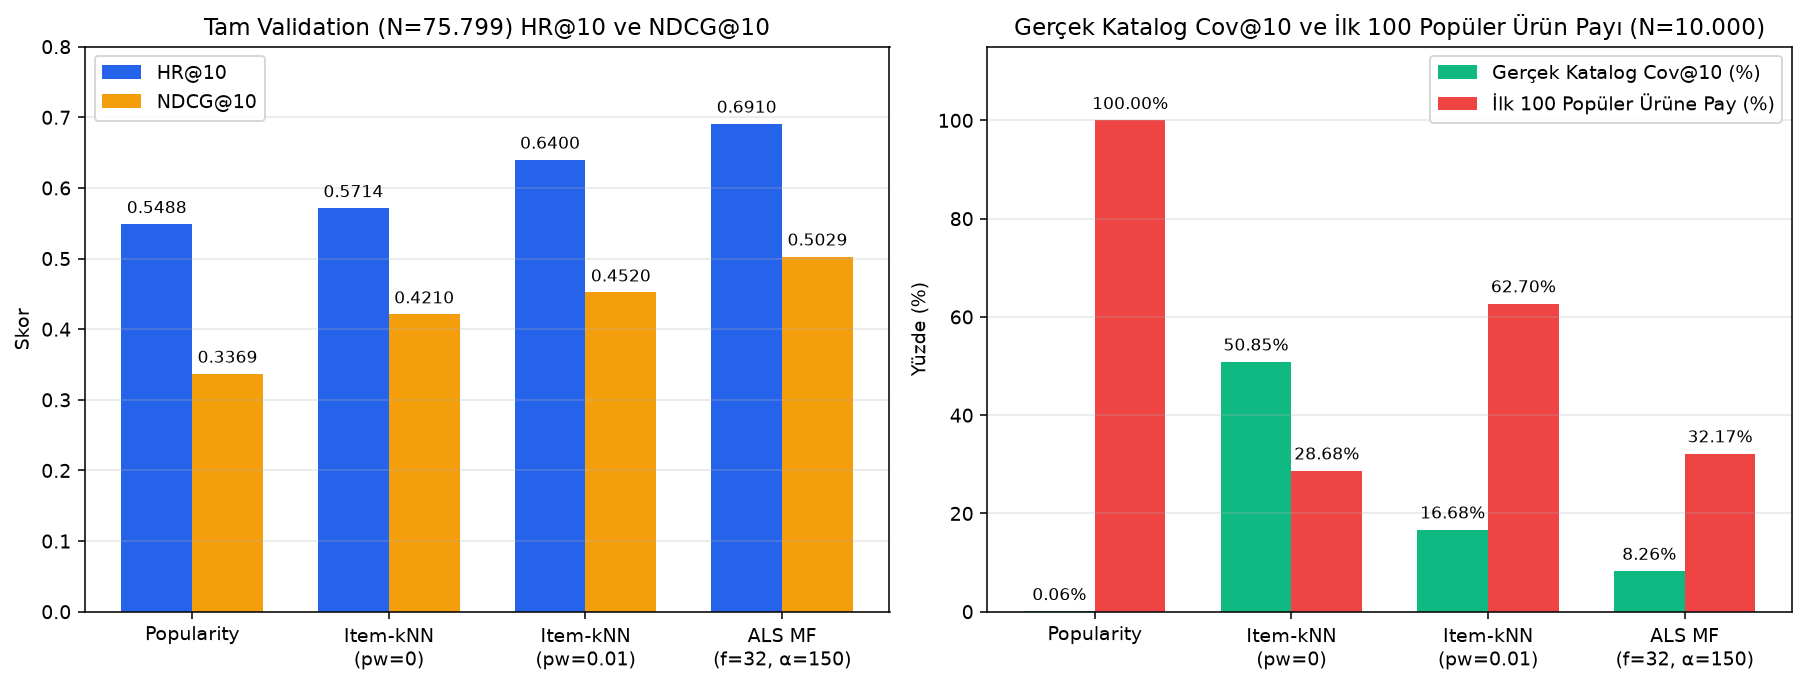

### 2. Popülerlik Kovalarına Göre HR@10 ve NDCG@10 (`figures/mf_02_pop_buckets_hr_ndcg.png`)

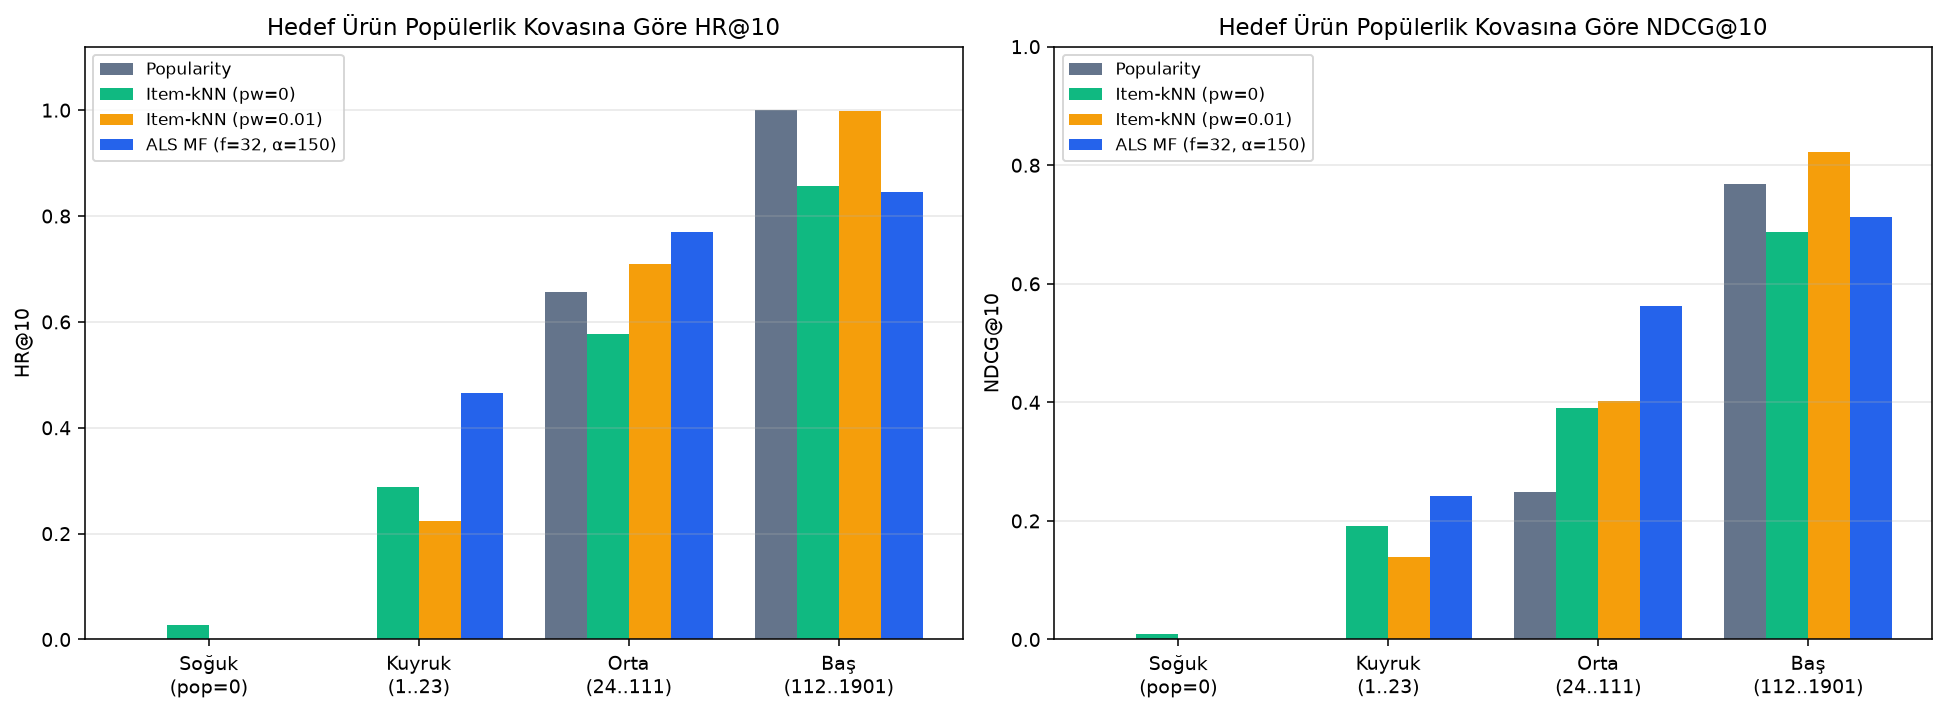

### 3. Doğruluk (NDCG@10) vs Gerçek Katalog Kapsamı (Coverage@10) (`figures/mf_03_ndcg_vs_catalog_coverage.png`)

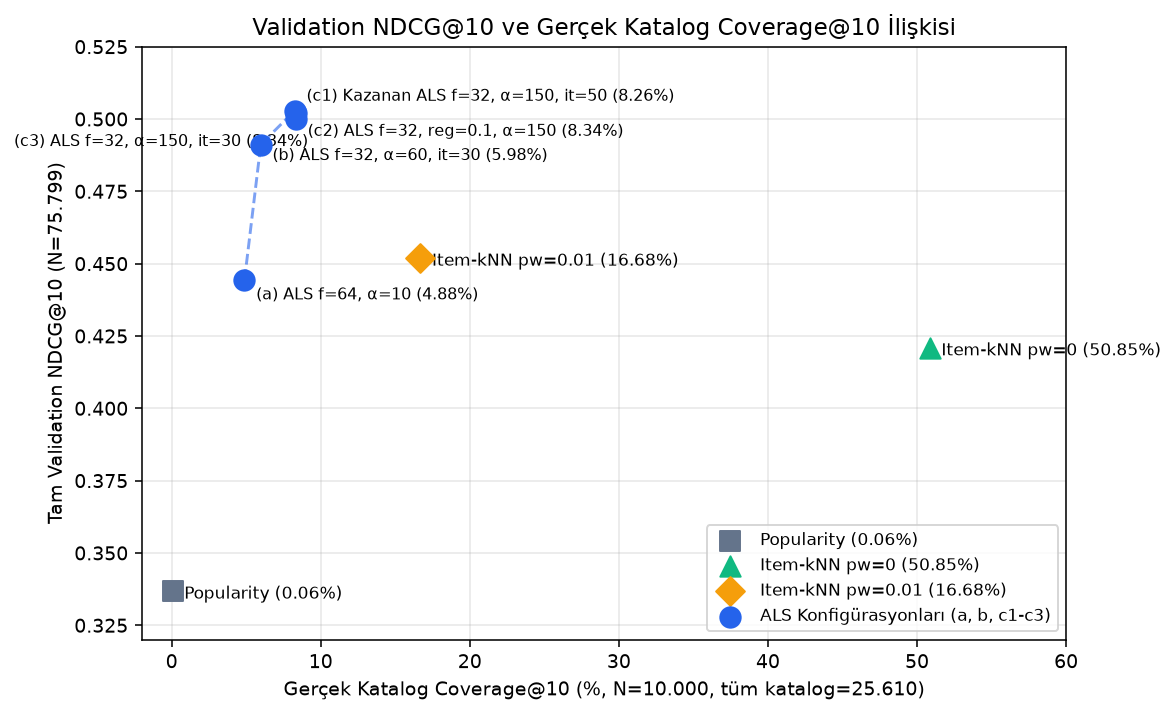

### 4. Ürün Popülerlik Yüzdeliğine Göre Kümülatif Öneri Payı (`figures/mf_04_cumulative_pop_percentile.png`)

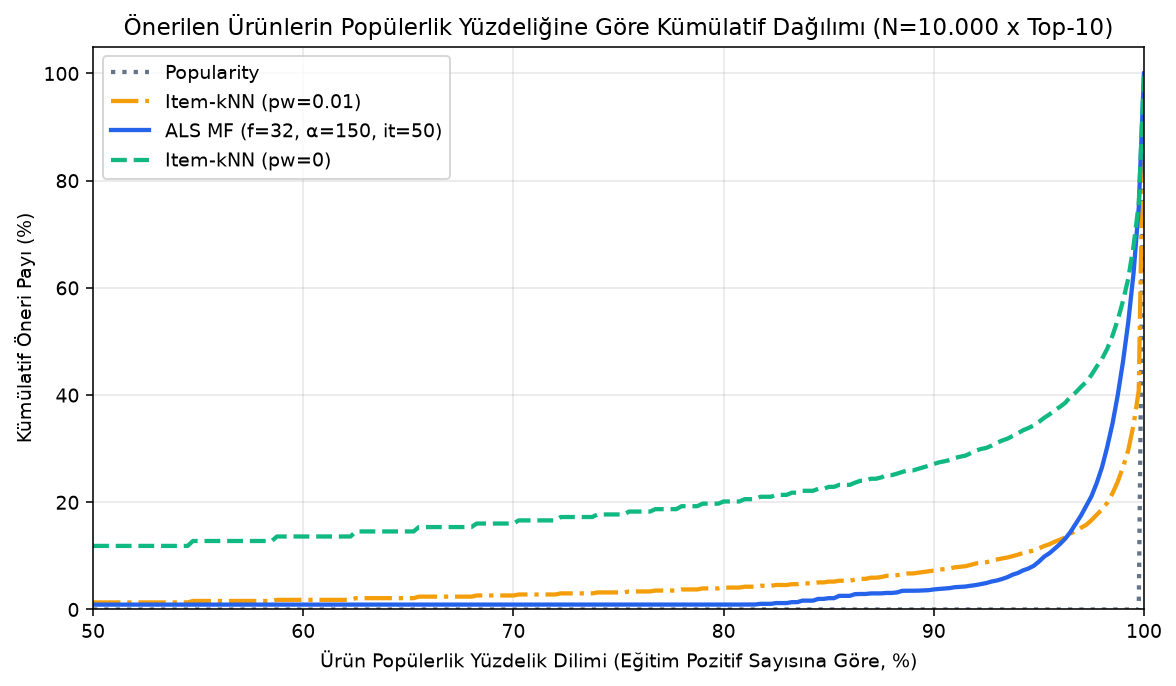

### 5. ALS Grid Araması (Stage 1-3): Alpha x Factors NDCG@10 Isı Haritası (`figures/mf_05_grid_heatmap_alpha_factors.png`)

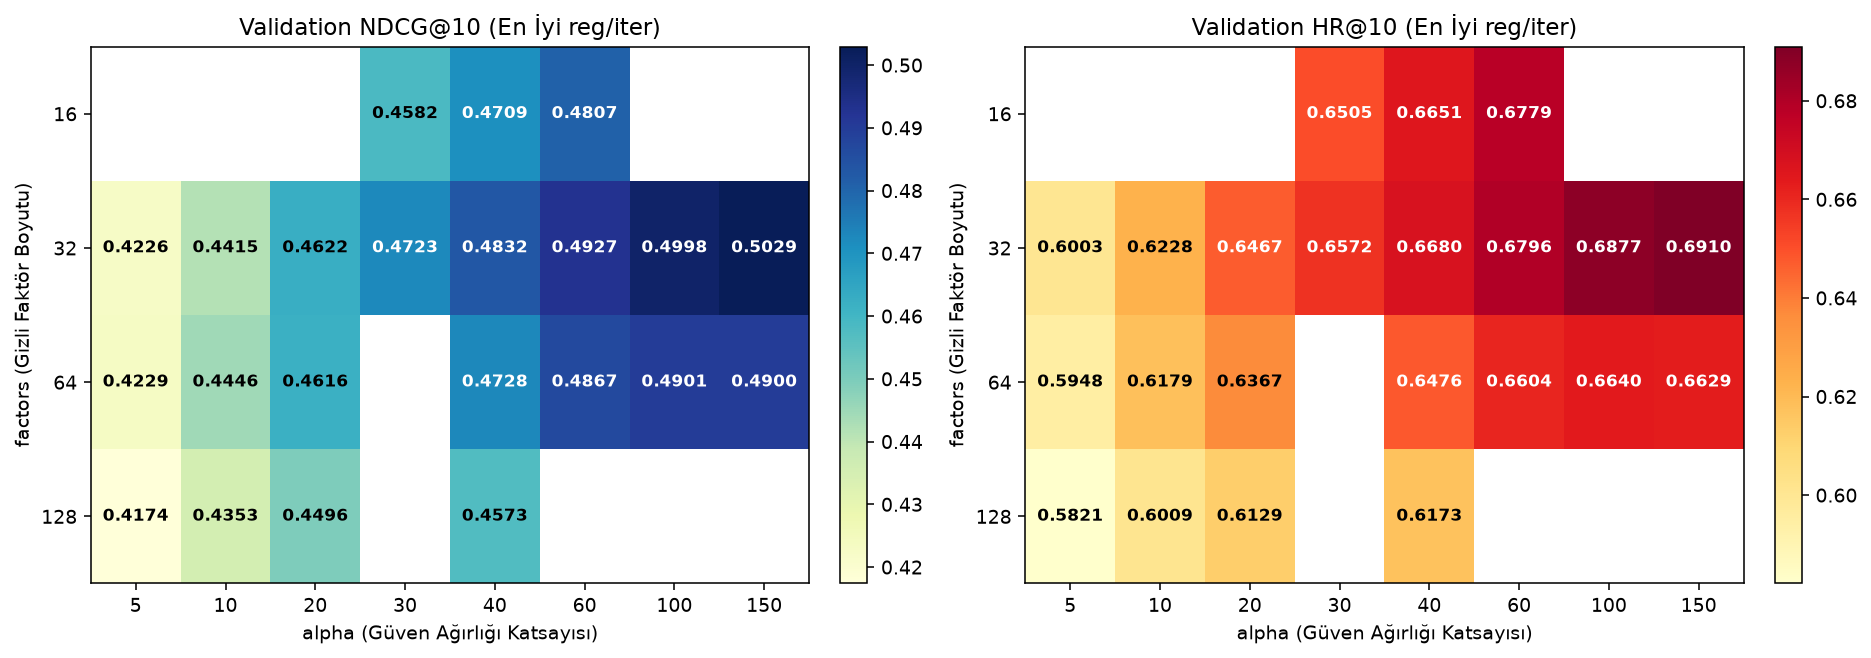

In [10]:
fig_files = [
    ('1. Ana Sıralama Metrikleri (Validation, N = 75.799)', 'mf_01_main_metrics_bar.png'),
    ('2. Popülerlik Kovalarına Göre HR@10 ve NDCG@10', 'mf_02_pop_buckets_hr_ndcg.png'),
    ('3. Doğruluk (NDCG@10) vs Gerçek Katalog Kapsamı (Coverage@10)', 'mf_03_ndcg_vs_catalog_coverage.png'),
    ('4. Ürün Popülerlik Yüzdeliğine Göre Kümülatif Öneri Payı', 'mf_04_cumulative_pop_percentile.png'),
    ('5. ALS Grid Araması (Stage 1-3): Alpha x Factors NDCG@10 Isı Haritası', 'mf_05_grid_heatmap_alpha_factors.png'),
]

for title, fname in fig_files:
    display(Markdown(f'### {title} (`figures/{fname}`)'))
    display(Image(filename=str(PROJECT_ROOT / 'figures' / fname)))

---
## h) Model Yorumu: Doğruluk, Hız, Bellek, Yeni Kullanıcı ve Hibrit Katman Hipotezi

1. **Sıralama Doğruluğu (`NDCG@10 = 0.5029`, `HR@10 = 0.6910`):**
   - `ALS MF`, `N = 75.799` validation kullanıcısında **HR@10 = 0.6910** ve **NDCG@10 = 0.5029** ile `Item-kNN (pw=0.01)` modelini (`HR@10 = 0.6400`, `NDCG@10 = 0.4520`) **+5.10 puan HR@10** ve **+5.09 puan NDCG@10** geçmiştir.
   - Bu kazanç **Kuyruk (`pop = 1..23`, HR@10: `0.4654` vs `0.2231`, +24.23 puan)** ve **Orta (`pop = 24..111`, HR@10: `0.7703` vs `0.7088`, +6.15 puan)** popülerlik kovalarından kaynaklanmaktadır. Buna karşılık **Baş (`pop = 112..1.901`)** kovasında `ALS MF` (**HR@10 = 0.8463**), popülerliği taklit eden `Item-kNN (pw=0.01)` modelinin (**HR@10 = 0.9985**) **-15.22 puan** gerisinde kalmaktadır.
2. **Gerçek Katalog Kapsamı ve Hibrit Katman Hipotezi:**
   - `ALS MF`, `10.000` canlı kullanıcıda 25.610 ürünlük tam katalogda **%8.26 (`2.116` benzersiz ürün)** gerçek katalog kapsamına sahiptir; bu oran `Item-kNN (pw=0.0)` (**%50.85**, `13.022` ürün) ve `Item-kNN (pw=0.01)` (**%16.68**, `4.272` ürün) modellerinden daha düşüktür (ilk 100 popüler ürüne verilen pay `ALS MF`'de **%32.17**, `Item-kNN pw=0.01`'de **%62.70**'tir).
   - **HİPOTEZ:** Hibrit (CF + Content-Based) katmanda, daha düşük/farklı alpha veya düzenlileştirme ayarlı bir MF ya da metin/kategori/platform özniteliklerini kullanan Content-Based (CB) modelin eklenmesiyle gerçek katalog kapsamının genişletilebileceği bir **HİPOTEZ** olarak öne sürülmektedir (hibrit birleştirme aşamasında test edilecektir).
3. **Hız, Bellek ve Uygulanabilirlik:**
   - Ayrı taze süreçlerde yapılan iki tekrarlı ölçümlerde `ALS MF` tam katalog önerisinde kullanıcı başına ortalama **3.918 ms** (10k kullanıcı **39.18 sn**), eğitimde **32.62 sn**, süreç RSS artışında **+33.33 MB** ve diskte **15.96 MB** ile çalışmaktadır.
4. **Yeni Kullanıcı Tercih Formu (`score_from_items`):**
   - Eğitimde en az 5 pozitif etkileşimi olan `5.000` validation kullanıcısında, 3 oyunda `Item-kNN (pw=0)` HR@10'da Popularity'nin altında kalırken (0.5286 vs 0.5460), `MF-ridge` **HR@10 = 0.6624 / NDCG@10 = 0.4704** ile `Item-kNN (pw=0.01)` modelini **+5.12 puan HR@10 ($z = +6.92$)** farkla geçmiştir.

---
## i) Teknik Tasarım Kararları ve Metodolojik Riskler

1. **`float32` Sayısal Gürültü Sıfırlama (`norm < 1e-4`):**
   - `implicit` kütüphanesinin çözücüsü, pozitif etkileşimi sıfır olan ürünlerde bile `float32` yuvarlama hataları nedeniyle `~1e-7` mertebesinde sıfırdan farklı gürültü vektörleri bırakabilmektedir. `ALSModel.fit()` içinde pozitif etkileşim sayısı `0` olan ürünlerin yanı sıra faktör normu `||v_i||_2 < 1e-4` olan ürünler açıkça `0.0`'a sıfırlanarak gürültü sıralaması önlenmiştir.
2. **Katlama (`Fold-in`) Seçimi (`ridge` vs `mean`):**
   - Yeni kullanıcı vektörü hesaplanırken basit ortalama (`mean`), seçilen tüm ürünlere eşit ağırlık verir ve arka plan popülerlik kovaryansını ($V^T V$) dikkate almaz (`3 oyunda NDCG@10 = 0.4389`, `100 Aday Havuz Cov@10 = %29.23`). Buna karşılık `ridge` çözümü $(V^T V + \alpha V_S^T V_S + \lambda I)^{-1} (1 + \alpha) V_S^T \mathbf{1}$ negatif örneklerin kovaryansını hesaba katarak **3 oyunda NDCG@10 = 0.4704 (+0.0314, $z = +8.45$)** ve **100 Aday Havuz Cov@10 = %57.31** sağlamıştır.
3. **İkili Güven Matrisi ($c_{ui} = 1 + \alpha r_{ui}$) ve Açık `rating` Büyüklüğünün Kullanılmaması:**
   - Proje veri sözleşmesi gereği `interaction_matrix` yalnızca `rating >= 4` (`label == 1`) etkileşimlerini `1.0` olarak tutar; 4 yıldız ile 5 yıldız arasındaki büyüklük farkı veya `rating < 4` (`label == 0`) negatif puanlar güven matrisinde kullanılmamıştır (`label == 0` ürünler yalnızca `seen_matrix` üzerinden öneri filtresinde kullanılır). Bu karar tüm CF modelleri (`Popularity`, `Item-kNN`, `ALS MF`) arasında tam girdi tutarlılığı sağlar.
4. **Stage 3 Kenarında (`alpha = 150, iterations = 50`) Durma Gerekçesi:**
   - `factors=32, reg=0.01, iter=30` için `alpha` artışının `NDCG@10` kazancı: `alpha 5 -> 20` (**+0.0222**), `20 -> 40` (**+0.0175**), `40 -> 60` (**+0.0080**), `60 -> 100` (**+0.0071**) ve `100 -> 150` (**+0.0031**); `alpha=150`'de `iter 30 -> 50` kazancı ise **+0.0015** (`0.5014 -> 0.5029`) olmuştur.
   - Marjinal `NDCG@10` kazancının binde 1.5–3.1 bandına inmesi nedeniyle `alpha > 150` bölgesine geçilmemiştir.
5. **Çoklu Deneme İyimserliği (Multiple-Testing / Selection Optimism) Riski:**
   - Hiperparametre araması boyunca validation seti (`N = 75.799`) üzerinde Stage 1 (`36`), Stage 2 (`12`) ve Stage 3 (`24`) olmak üzere **toplam 72 farklı ALS konfigürasyonu** (+2 `fold-in` yöntemi) değerlendirilmiş ve en yüksek validation `NDCG@10` (`0.5029`) değerini veren model seçilmiştir.
   - Aynı validation seti üzerinde 72 deneme arasından maksimumun seçilmesi, seçilen modelin validation metriklerinde küçük bir **seçim iyimserliği (selection bias)** barındırma riski taşır (`N = 75.799` örneklem büyüklüğü nedeniyle tekil metrik standart hatası `SE ≈ 0.0017` düzeyindedir). Bu nedenle modelin gerçek genelleme performansı, yalnızca final aşamada **hiç dokunulmamış `test.csv` (`N = 74.021`)** üzerinde tek seferlik değerlendirme yapıldığında kesinleşecektir.